# Variables más relacionadas con el abandono (objetivo específico 1)

**Dueño:** Juanes · **Bloque 1** (sesiones del 30 de octubre al 1 de noviembre)

Regla: el notebook solo *muestra* resultados; la lógica vive en `src/churn/relacion.py` para que se pueda probar.

Mientras no se fusione la base limpia de Ianis se usa la base cruda (3150 filas). Cuando exista, basta cambiar `cargar_crudo()` por `cargar_limpio()` en la celda de carga y volver a correr todo.

In [1]:
import sys; sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import pandas as pd
from churn import config
from churn.datos import cargar_crudo
from churn.relacion import correlacion_con_churn, redundancias, tasa_por_categoria, vif_por_variable

df = cargar_crudo()
print(f"{len(df)} filas, tasa de abandono {df[config.OBJETIVO].mean():.1%}")

3150 filas, tasa de abandono 15.7%


## 1. ¿Qué tan relacionada está cada variable con el abandono?

`correlacion_con_churn` calcula dos correlaciones por variable: la **punto-biserial** (Pearson con un objetivo 0/1) y la de **Spearman** (sobre rangos, robusta a colas largas). Positiva = más abandono; negativa = menos.

In [2]:
corr = correlacion_con_churn(df)
corr.round(3)

,variable,grupo,pearson_pb,spearman,p_valor
0,quejas,servicio,0.532,0.532,0.000
1,estado,suscripcion,0.499,0.499,0.000
2,frecuencia_llamadas,uso,-0.303,-0.343,0.000
3,segundos_uso,uso,-0.299,-0.367,0.000
4,valor_cliente,suscripcion,-0.289,-0.361,0.000
5,numeros_distintos,uso,-0.279,-0.302,0.000
6,frecuencia_sms,uso,-0.221,-0.224,0.000
7,nivel_cobro,suscripcion,-0.202,-0.251,0.000
8,plan_tarifa,suscripcion,-0.106,-0.106,0.000
9,meses_suscripcion,suscripcion,-0.033,-0.035,0.067


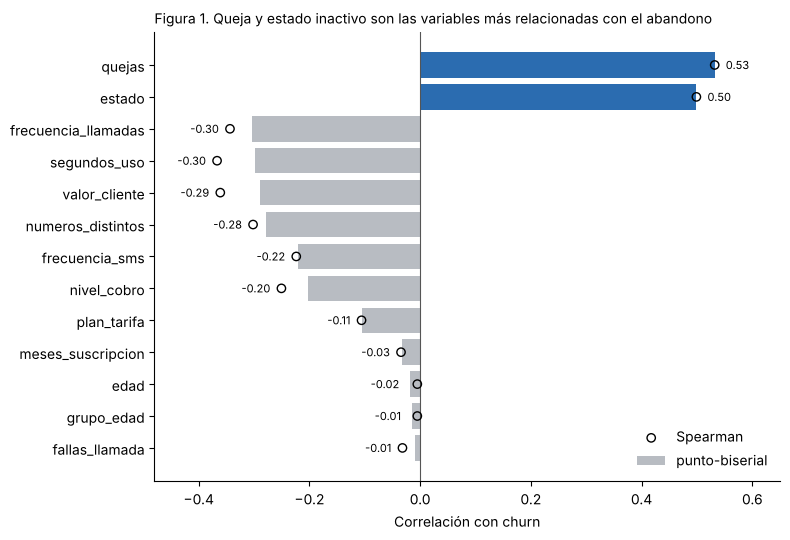

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
orden = corr.iloc[::-1]
colores = ['#2b6cb0' if v in ('quejas', 'estado') else '#b8bcc2' for v in orden['variable']]
ax.barh(orden['variable'], orden['pearson_pb'], color=colores, label='punto-biserial')
ax.scatter(orden['spearman'], orden['variable'], color='black', facecolors='none', zorder=3, label='Spearman')
ax.axvline(0, color='#555', lw=0.8)
for y, (v, sp) in enumerate(zip(orden['pearson_pb'], orden['spearman'])):
    borde = max(v, sp, 0) if v >= 0 else min(v, sp, 0)
    ax.text(borde + (0.02 if v >= 0 else -0.02), y, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
ax.set_xlim(-0.48, 0.65)
ax.set_xlabel('Correlación con churn')
ax.set_title('Figura 1. Queja y estado inactivo son las variables más relacionadas con el abandono', loc='left', fontsize=10)
ax.legend(frameon=False, loc='lower right')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout()

**Lectura.** Queja (0,53) y estado (0,50) se separan del resto. Las cuatro variables de uso tienen relación negativa moderada (−0,22 a −0,30): quien usa menos el servicio abandona más. Fallas de llamada, edad y antigüedad están cerca de cero. Por rangos (círculos), `segundos_uso` y `valor_cliente` pesan algo más que por Pearson: las colas largas atenuaban su relación.

## 2. La misma relación, en porcentajes

`tasa_por_categoria` dice qué proporción abandona en cada nivel de una variable. Es la forma de contarlo al equipo de retención.

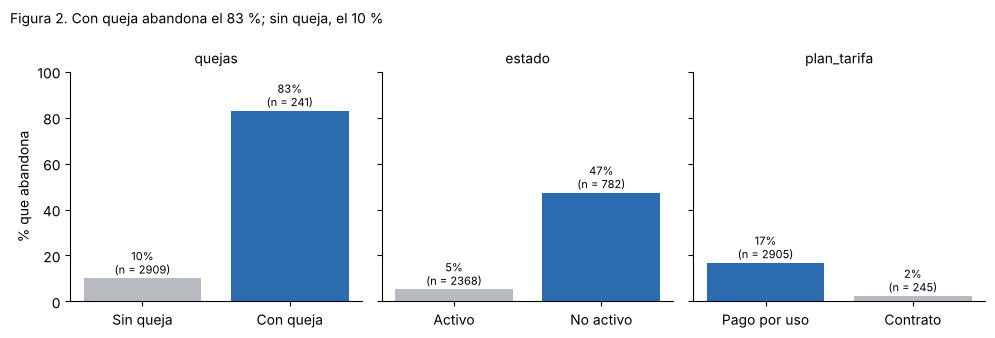

In [4]:
etiquetas = {'quejas': {0: 'Sin queja', 1: 'Con queja'}, 'estado': {1: 'Activo', 2: 'No activo'},
             'plan_tarifa': {1: 'Pago por uso', 2: 'Contrato'}}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, col in zip(axes, ['quejas', 'estado', 'plan_tarifa']):
    t = tasa_por_categoria(df, col)
    nombres = [etiquetas[col][n] for n in t['nivel']]
    barras = ax.bar(nombres, t['tasa_churn'] * 100, color=['#b8bcc2', '#2b6cb0'] if col != 'plan_tarifa' else ['#2b6cb0', '#b8bcc2'])
    for b, tasa, n in zip(barras, t['tasa_churn'], t['n']):
        ax.text(b.get_x() + b.get_width() / 2, tasa * 100 + 2, f'{tasa:.0%}\n(n = {n})', ha='center', fontsize=8)
    ax.set_title(col, fontsize=10)
    ax.set_ylim(0, 100)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('% que abandona')
fig.suptitle('Figura 2. Con queja abandona el 83 %; sin queja, el 10 %', x=0.01, ha='left', fontsize=10)
plt.tight_layout()

In [5]:
tasa_por_categoria(df, 'nivel_cobro').assign(tasa_churn=lambda t: (t['tasa_churn'] * 100).round(1))

,nivel,n,tasa_churn
0,0,1768,23.8
1,1,617,7.0
2,2,395,5.8
3,3,199,3.5
4,4,76,1.3
5,5,30,0.0
6,6,11,0.0
7,7,14,0.0
8,8,19,0.0
9,9,14,0.0


**Lectura.** La diferencia por queja es de 73 puntos y por estado de 42. Los clientes de contrato casi no abandonan (2 %), pero son pocos (245). En nivel de cobro el abandono cae de 24 % en el nivel 0 a 0 % desde el nivel 5; esos niveles altos tienen entre 7 y 30 clientes, así que la tasa es inestable.

## 3. ¿Hay variables que repiten la misma información?

`redundancias` busca pares con |r| ≥ 0,8 y `vif_por_variable` calcula el VIF de cada predictor (1 = nada redundante; más de 10 = redundancia seria). Se quita `grupo_edad` por la decisión del 29 de octubre.

In [6]:
base = df.drop(columns=[config.COLUMNA_EDAD_A_QUITAR])
redundancias(base).round(2)

,var_1,var_2,r,vif_1,vif_2
0,segundos_uso,frecuencia_llamadas,0.95,22.78,18.84
1,frecuencia_sms,valor_cliente,0.92,43.37,55.74


In [7]:
vif_por_variable(base).round(1).to_frame()

,vif
valor_cliente,55.7
frecuencia_sms,43.4
segundos_uso,22.8
frecuencia_llamadas,18.8
nivel_cobro,3.2
fallas_llamada,2.9
numeros_distintos,2.4
edad,2.2
estado,1.8
plan_tarifa,1.6


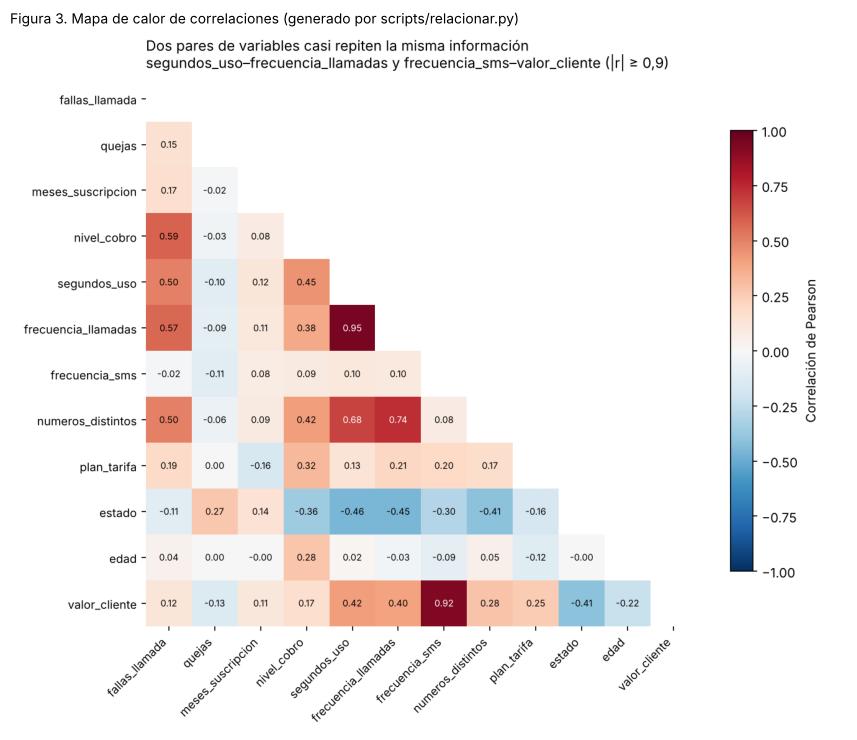

In [8]:
from PIL import Image
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(Image.open('../reports/figures/correlaciones.png'))
ax.axis('off')
ax.set_title('Figura 3. Mapa de calor de correlaciones (generado por scripts/relacionar.py)', loc='left', fontsize=10)
plt.tight_layout()

**Lectura.** `segundos_uso` y `frecuencia_llamadas` (r = 0,95) y `frecuencia_sms` y `valor_cliente` (r = 0,92) casi repiten la misma información. En una regresión logística eso vuelve inestables los coeficientes. La propuesta para la reunión 1 (en `docs/decisiones.md`) es quitar `valor_cliente` y `frecuencia_llamadas`; con eso ningún VIF pasa de 2,3.

In [9]:
propuesta = ['fallas_llamada', 'quejas', 'segundos_uso', 'frecuencia_sms', 'numeros_distintos',
             'meses_suscripcion', 'nivel_cobro', 'plan_tarifa', 'estado', 'edad']
vif_por_variable(base[propuesta + ['fila_original', 'churn']]).round(2).to_frame()

,vif
segundos_uso,2.24
nivel_cobro,2.22
fallas_llamada,2.15
numeros_distintos,2.08
estado,1.77
plan_tarifa,1.28
edad,1.21
frecuencia_sms,1.18
meses_suscripcion,1.17
quejas,1.14
